# Customer Shopping Behaviour

## Importing and Understanding the Dataset

In [3]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
file_path = "rawdata_customer_shopping_intership26sep.csv"
customer_shopping_data = pd.read_csv(file_path)

# Display the first five records
display(customer_shopping_data.head())

# Check dataset dimensions
print("Dataset Shape:", customer_shopping_data.shape)

# Display column names
print("\nColumn Names:")
print(customer_shopping_data.columns.tolist())

# Check data types and non-null counts
print("\nDataset Information:")
customer_shopping_data.info()

# Generate descriptive statistics
print("\nDescriptive Statistics:")
display(customer_shopping_data.describe(include="all").T)

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


Dataset Shape: (99457, 10)

Column Names:
['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity', 'price', 'payment_method', 'invoice_date', 'shopping_mall']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB

Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
invoice_no,99457,99457,I138884,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,99457,99457,C241288,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,99457,2,Female,59482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,99457.0,NaN,NaN,NaN,43.427089,14.990054,18.0,30.0,43.0,56.0,69.0
category,99457,8,Clothing,34487,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,99457.0,NaN,NaN,NaN,3.003429,1.413025,1.0,2.0,3.0,4.0,5.0
price,99457.0,NaN,NaN,NaN,689.256321,941.184567,5.23,45.45,203.3,1200.32,5250.0
payment_method,99457,3,Cash,44447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
invoice_date,99457,797,24/11/2021,159,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shopping_mall,99457,10,Mall of Istanbul,19943,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Display column names
print("\nColumn Names:")
print(customer_shopping_data.columns.tolist())


Column Names:
['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity', 'price', 'payment_method', 'invoice_date', 'shopping_mall']


In [5]:

# Create age groups
customer_shopping_data["age_group"] = pd.cut(
    customer_shopping_data["age"],
    bins=[17, 25, 35, 45, 55, 70],
    labels=["18–25", "26–35", "36–45", "46–55", "56–69"]
)

# Check the age groups
display(customer_shopping_data[["age", "age_group"]].head(10))

# Check the number of customers in each age group
display(customer_shopping_data["age_group"].value_counts().sort_index())


,age,age_group
0,28,26–35
1,21,18–25
2,20,18–25
3,66,56–69
4,53,46–55
5,28,26–35
6,49,46–55
7,32,26–35
8,69,56–69
9,60,56–69


age_group
18–25    15359
26–35    19059
36–45    19436
46–55    19016
56–69    26587
Name: count, dtype: int64

In [7]:
# Display column names
print("\nColumn Names:")
print(customer_shopping_data.columns.tolist())


Column Names:
['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity', 'price', 'payment_method', 'invoice_date', 'shopping_mall', 'age_group']


## Checking Missing Values and Duplicate Records

In [6]:
# Check missing values in each column
missing_values_summary = customer_shopping_data.isnull().sum()

print("Missing Values by Column:")
display(missing_values_summary.to_frame(name="Missing Values"))

# Check total missing values
print("Total Missing Values:", customer_shopping_data.isnull().sum().sum())

# Check duplicate rows
duplicate_records_count = customer_shopping_data.duplicated().sum()

print("\nDuplicate Records:", duplicate_records_count)

# Check duplicate invoice numbers
duplicate_invoice_count = customer_shopping_data["invoice_no"].duplicated().sum()

print("Duplicate Invoice Numbers:", duplicate_invoice_count)

# Check duplicate customer IDs
duplicate_customer_count = customer_shopping_data["customer_id"].duplicated().sum()

print("Duplicate Customer IDs:", duplicate_customer_count)

Missing Values by Column:


,Missing Values
invoice_no,0
customer_id,0
gender,0
age,0
category,0
quantity,0
price,0
payment_method,0
invoice_date,0
shopping_mall,0


Total Missing Values: 0

Duplicate Records: 0
Duplicate Invoice Numbers: 0
Duplicate Customer IDs: 0


## Data Type Validation and Date Conversion

In [7]:
# Check current data types
print("Data Types Before Conversion:")
display(customer_shopping_data.dtypes.to_frame(name="Data Type"))

# Convert invoice_date to datetime format
customer_shopping_data["invoice_date"] = pd.to_datetime(
    customer_shopping_data["invoice_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Check data types after conversion
print("\nData Types After Conversion:")
display(customer_shopping_data.dtypes.to_frame(name="Data Type"))

# Check whether any dates failed to convert
invalid_dates_count = customer_shopping_data["invoice_date"].isna().sum()

print("\nInvalid Dates After Conversion:", invalid_dates_count)

# Display earliest and latest transaction dates
print("Earliest Transaction Date:", customer_shopping_data["invoice_date"].min())
print("Latest Transaction Date:", customer_shopping_data["invoice_date"].max())

Data Types Before Conversion:


,Data Type
invoice_no,object
customer_id,object
gender,object
age,int64
category,object
quantity,int64
price,float64
payment_method,object
invoice_date,object
shopping_mall,object



Data Types After Conversion:


,Data Type
invoice_no,object
customer_id,object
gender,object
age,int64
category,object
quantity,int64
price,float64
payment_method,object
invoice_date,datetime64[ns]
shopping_mall,object



Invalid Dates After Conversion: 0
Earliest Transaction Date: 2021-01-01 00:00:00
Latest Transaction Date: 2023-03-08 00:00:00


## Checking Data Quality and Validating Values

In [8]:
# Check numerical columns for invalid values

# Age validation
invalid_age_count = (
    (customer_shopping_data["age"] < 0) |
    (customer_shopping_data["age"] > 100)
).sum()

# Quantity validation
invalid_quantity_count = (
    customer_shopping_data["quantity"] <= 0
).sum()

# Transaction amount validation
invalid_price_count = (
    customer_shopping_data["price"] <= 0
).sum()

# Check for blank text values
text_columns = customer_shopping_data.select_dtypes(
    include="object"
).columns

blank_values_count = (
    customer_shopping_data[text_columns]
    .apply(lambda column: column.astype("string").str.strip().eq("").sum())
    .sum()
)

# Display validation results
data_quality_summary = pd.DataFrame({
    "Validation Check": [
        "Invalid ages (below 0 or above 100)",
        "Invalid quantities (zero or negative)",
        "Invalid transaction amounts (zero or negative)",
        "Blank text values"
    ],
    "Issue Count": [
        invalid_age_count,
        invalid_quantity_count,
        invalid_price_count,
        blank_values_count
    ]
})

display(data_quality_summary)

# Count unique values in every column
unique_values_summary = customer_shopping_data.nunique()

print("Unique Values in Each Column:")
display(unique_values_summary.to_frame(name="Unique Count"))

# Check unique values in categorical columns
categorical_columns = customer_shopping_data.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(customer_shopping_data[column].unique())

    # Count unique values in each column
unique_values_count = customer_shopping_data.nunique()

print("Count of Unique Values in Each Column:")
display(unique_values_count.to_frame(name="Unique Value Count"))

,Validation Check,Issue Count
0,Invalid ages (below 0 or above 100),0
1,Invalid quantities (zero or negative),0
2,Invalid transaction amounts (zero or negative),0
3,Blank text values,0


Unique Values in Each Column:


,Unique Count
invoice_no,99457
customer_id,99457
gender,2
age,52
category,8
quantity,5
price,40
payment_method,3
invoice_date,797
shopping_mall,10



invoice_no:
['I138884' 'I317333' 'I127801' ... 'I824010' 'I702964' 'I232867']

customer_id:
['C241288' 'C111565' 'C266599' ... 'C103292' 'C800631' 'C273973']

gender:
['Female' 'Male']

category:
['Clothing' 'Shoes' 'Books' 'Cosmetics' 'Food & Beverage' 'Toys'
 'Technology' 'Souvenir']

payment_method:
['Credit Card' 'Debit Card' 'Cash']

shopping_mall:
['Kanyon' 'Forum Istanbul' 'Metrocity' 'Metropol AVM' 'Istinye Park'
 'Mall of Istanbul' 'Emaar Square Mall' 'Cevahir AVM' 'Viaport Outlet'
 'Zorlu Center']
Count of Unique Values in Each Column:


,Unique Value Count
invoice_no,99457
customer_id,99457
gender,2
age,52
category,8
quantity,5
price,40
payment_method,3
invoice_date,797
shopping_mall,10


## Statistical Summary of Numerical Columns

In [9]:
# Select numerical columns
numerical_columns = customer_shopping_data.select_dtypes(
    include=np.number
)

# Generate statistical summary
numerical_summary = numerical_columns.describe().T

# Add median for better understanding
numerical_summary["median"] = numerical_columns.median()

display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,median
age,99457.0,43.43,14.99,18.00,30.00,43.0,56.00,69.0,43.0
quantity,99457.0,3.00,1.41,1.00,2.00,3.0,4.00,5.0,3.0
price,99457.0,689.26,941.18,5.23,45.45,203.3,1200.32,5250.0,203.3


## Outlier Detection Using the IQR Method

In [10]:
# Select numerical columns for outlier detection
columns_to_check = ["age", "quantity", "price"]

outlier_summary = []

for column in columns_to_check:
    first_quartile = customer_shopping_data[column].quantile(0.25)
    third_quartile = customer_shopping_data[column].quantile(0.75)

    interquartile_range = third_quartile - first_quartile

    lower_bound = first_quartile - 1.5 * interquartile_range
    upper_bound = third_quartile + 1.5 * interquartile_range

    outlier_count = (
        (customer_shopping_data[column] < lower_bound) |
        (customer_shopping_data[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Column": column,
        "Q1": first_quartile,
        "Q3": third_quartile,
        "IQR": interquartile_range,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": (
            outlier_count / len(customer_shopping_data) * 100
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,30.00,56.00,26.00,-9.00,95.00,0,0.00
1,quantity,2.00,4.00,2.00,-1.00,7.00,0,0.00
2,price,45.45,1200.32,1154.87,-1686.85,2932.62,5024,5.05


In [13]:
# Step 1: Calculate quartiles
price_first_quartile = customer_shopping_data["price"].quantile(0.25)
price_third_quartile = customer_shopping_data["price"].quantile(0.75)

# Step 2: Calculate IQR
price_iqr = price_third_quartile - price_first_quartile

# Step 3: Calculate outlier boundaries
price_lower_boundary = price_first_quartile - (1.5 * price_iqr)
price_upper_boundary = price_third_quartile + (1.5 * price_iqr)

# Step 4: Display results
print("First Quartile (Q1):", price_first_quartile)
print("Third Quartile (Q3):", price_third_quartile)
print("IQR:", price_iqr)
print("Lower Boundary:", price_lower_boundary)
print("Upper Boundary:", price_upper_boundary)

# Step 5: Identify potential price outliers
price_outlier_records = customer_shopping_data[
    (customer_shopping_data["price"] < price_lower_boundary) |
    (customer_shopping_data["price"] > price_upper_boundary)
]

print("\nNumber of Potential Price Outliers:", len(price_outlier_records))

# Step 6: Display the 10 highest potential price outliers
display(
    price_outlier_records[
        ["invoice_no", "category", "quantity", "price", "shopping_mall"]
    ]
    .sort_values("price", ascending=False)
    .head(10)
)

First Quartile (Q1): 45.45
Third Quartile (Q3): 1200.32
IQR: 1154.87
Lower Boundary: -1686.8549999999998
Upper Boundary: 2932.625

Number of Potential Price Outliers: 5024


,invoice_no,category,quantity,price,shopping_mall
35953,I157646,Technology,5,5250.0,Kanyon
34961,I110383,Technology,5,5250.0,Mall of Istanbul
84678,I194668,Technology,5,5250.0,Mall of Istanbul
84753,I330059,Technology,5,5250.0,Emaar Square Mall
84777,I330320,Technology,5,5250.0,Kanyon
36507,I896663,Technology,5,5250.0,Mall of Istanbul
84813,I235480,Technology,5,5250.0,Metrocity
36464,I207330,Technology,5,5250.0,Mall of Istanbul
84859,I135890,Technology,5,5250.0,Cevahir AVM
36269,I257361,Technology,5,5250.0,Metrocity


### Interpretation of Price Outliers

The Interquartile Range (IQR) method identified **5,024 potential outliers**, representing approximately **5.05%** of the 99,457 records.

The first quartile (Q1) was 45.45, the third quartile (Q3) was 1,200.32, and the IQR was 1,154.87. Based on the IQR method, transactions above 2,932.625 were classified as potential upper outliers. The lower boundary was -1,686.855, which is below zero.

The highest observed transaction amount was 5,250.00. The sample of high-value records includes Technology transactions, which may reflect the higher price of products in that category.

**Decision:** The potential outliers were retained because statistical outliers are not necessarily data-entry errors. Further validation would be required before removing or modifying any records.

In [34]:

outlier_category_analysis = (
    price_outlier_records.groupby("category")
    .agg(
        Outlier_Count=("invoice_no", "count"),
        Average_Price=("price", "mean"),
        Maximum_Price=("price", "max")
    )
    .sort_values("Outlier_Count", ascending=False)
    .round(2)
)

display(outlier_category_analysis)


,Outlier_Count,Average_Price,Maximum_Price
category,,,
Technology,3011,4197.21,5250.00
Shoes,2013,3000.85,3000.85


## Exploratory Data Analysis (EDA)

### Univariate Analysis of Numerical Columns

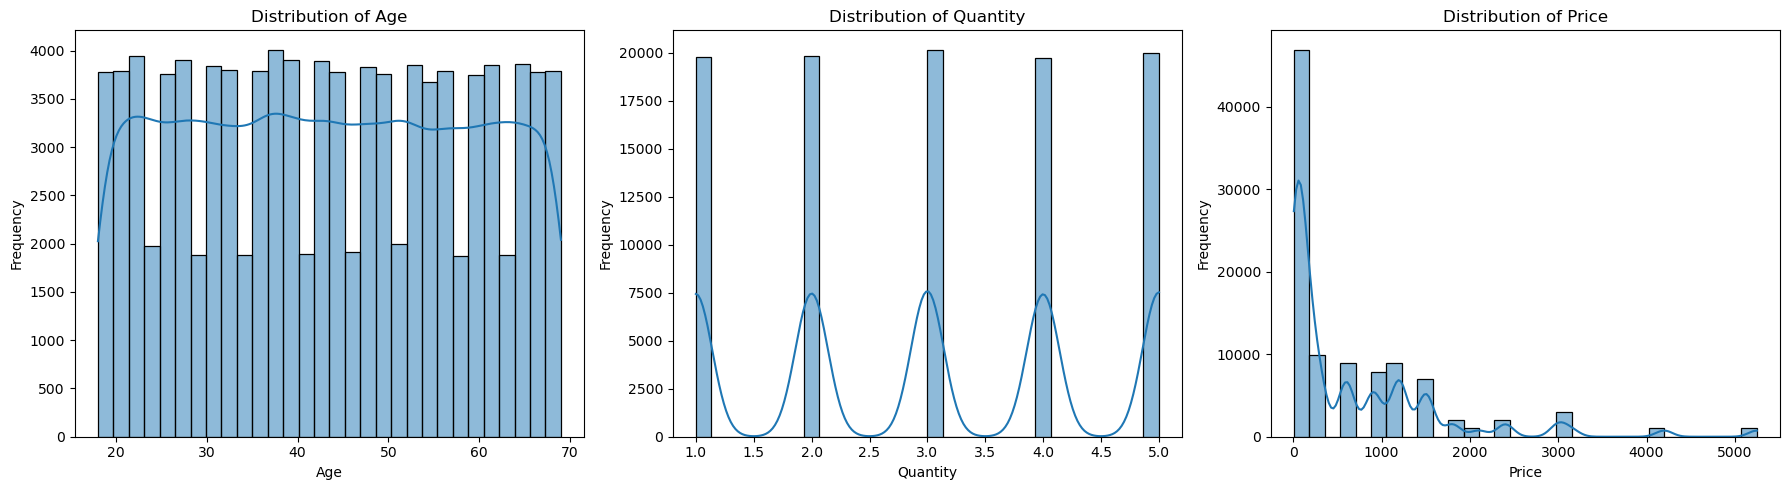

In [11]:
# Create visualizations for numerical columns
numerical_columns_to_plot = ["age", "quantity", "price"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for index, column in enumerate(numerical_columns_to_plot):
    sns.histplot(
        data=customer_shopping_data,
        x=column,
        bins=30,
        kde=True,
        ax=axes[index]
    )

    axes[index].set_title(f"Distribution of {column.title()}")
    axes[index].set_xlabel(column.title())
    axes[index].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Categorical Data Analysis


Distribution of Gender:


,Count,Percentage
gender,,
Female,59482,59.81
Male,39975,40.19



Distribution of Category:


,Count,Percentage
category,,
Clothing,34487,34.68
Cosmetics,15097,15.18
Food & Beverage,14776,14.86
Toys,10087,10.14
Shoes,10034,10.09
Souvenir,4999,5.03
Technology,4996,5.02
Books,4981,5.01



Distribution of Payment Method:


,Count,Percentage
payment_method,,
Cash,44447,44.69
Credit Card,34931,35.12
Debit Card,20079,20.19



Distribution of Shopping Mall:


,Count,Percentage
shopping_mall,,
Mall of Istanbul,19943,20.05
Kanyon,19823,19.93
Metrocity,15011,15.09
Metropol AVM,10161,10.22
Istinye Park,9781,9.83
Zorlu Center,5075,5.10
Cevahir AVM,4991,5.02
Forum Istanbul,4947,4.97
Viaport Outlet,4914,4.94


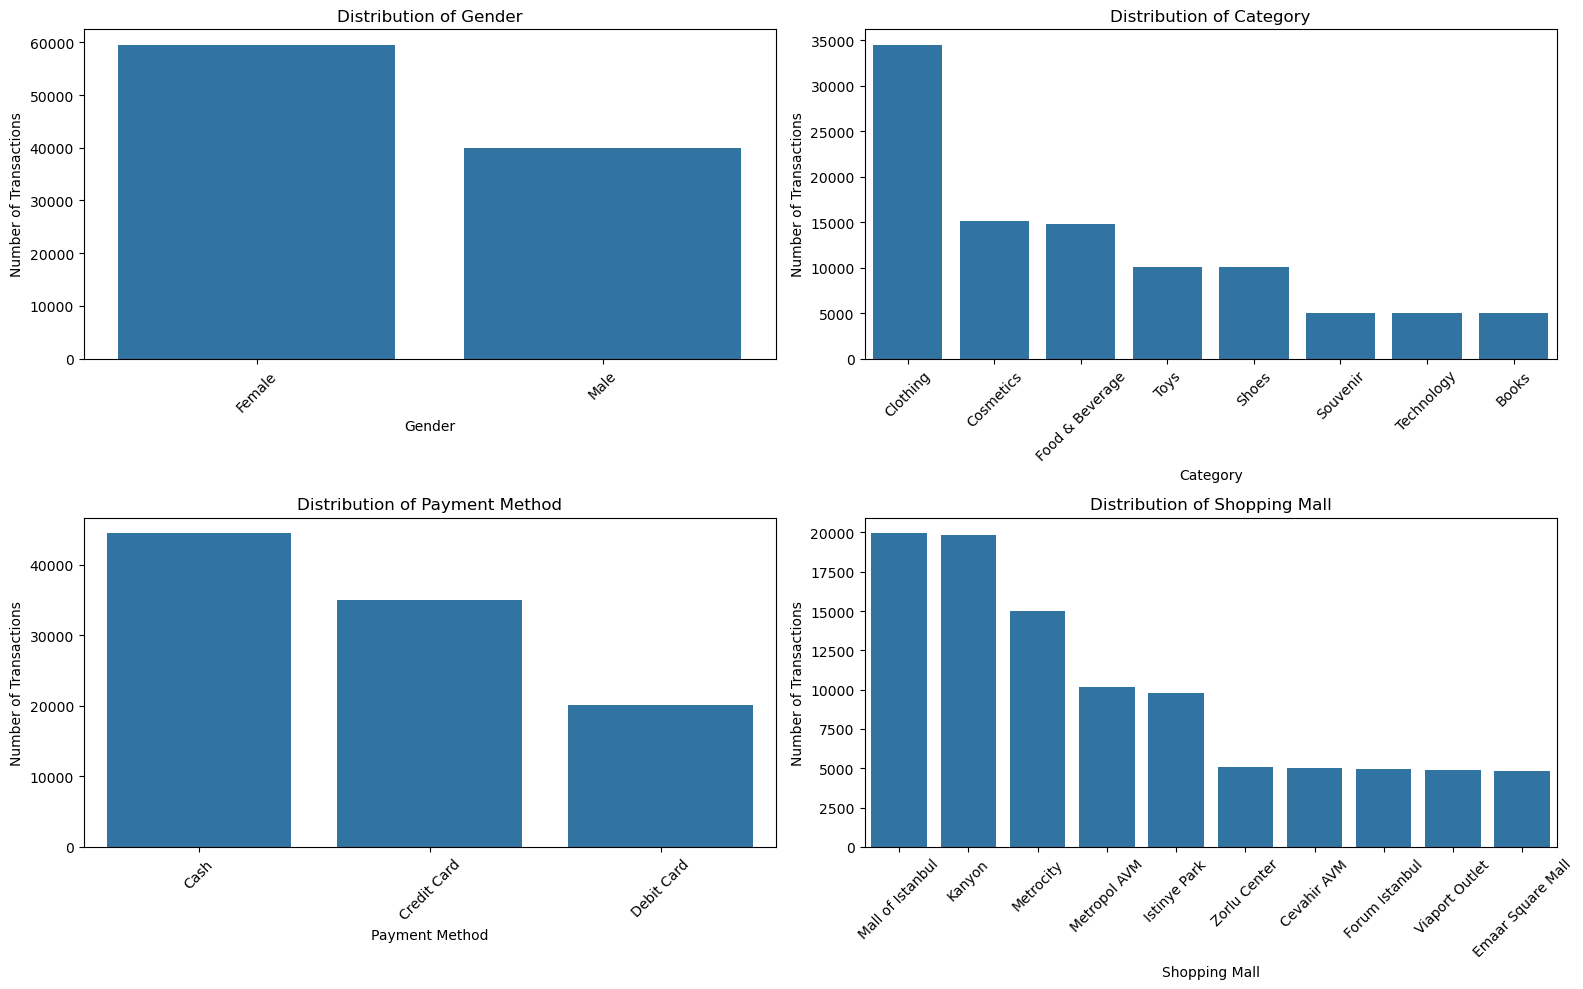

In [15]:
# Identify categorical columns
categorical_columns = [
    "gender",
    "category",
    "payment_method",
    "shopping_mall"
]

# Display value counts and percentages for each category
for column in categorical_columns:
    print(f"\nDistribution of {column.replace('_', ' ').title()}:")

    category_summary = pd.DataFrame({
        "Count": customer_shopping_data[column].value_counts(),
        "Percentage": (
            customer_shopping_data[column].value_counts(normalize=True) * 100
        ).round(2)
    })

    display(category_summary)

# Visualize categorical distributions
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for index, column in enumerate(categorical_columns):
    category_order = customer_shopping_data[column].value_counts().index

    sns.countplot(
        data=customer_shopping_data,
        x=column,
        order=category_order,
        ax=axes[index]
    )

    axes[index].set_title(
        f"Distribution of {column.replace('_', ' ').title()}"
    )
    axes[index].set_xlabel(column.replace("_", " ").title())
    axes[index].set_ylabel("Number of Transactions")
    axes[index].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Bivariate Analysis

#### Transaction Amount by Category

,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
category,,,,
Clothing,31075684.64,901.08,34487,103558
Shoes,18135336.89,1807.39,10034,30217
Technology,15772050.00,3156.94,4996,15021
Cosmetics,1848606.90,122.45,15097,45465
Toys,1086704.64,107.73,10087,30321
Food & Beverage,231568.71,15.67,14776,44277
Books,226977.30,45.57,4981,14982
Souvenir,174436.83,34.89,4999,14871


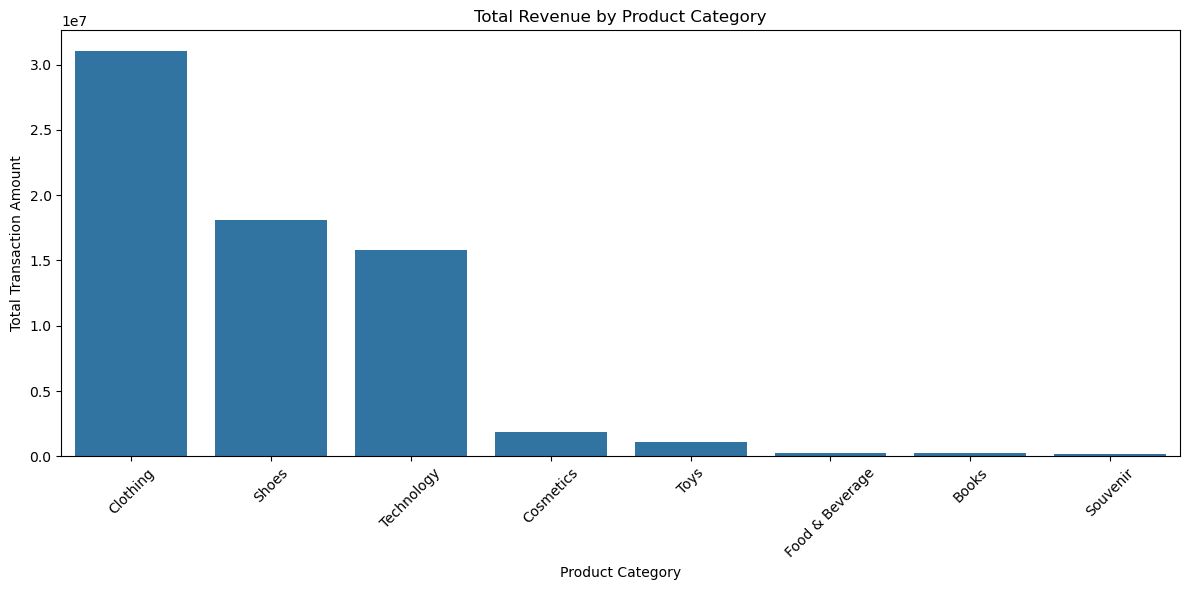

In [16]:
# Calculate transaction amount and transaction count by category
category_analysis = (
    customer_shopping_data
    .groupby("category")
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(category_analysis)

# Visualize total revenue by category
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_analysis.reset_index(),
    x="category",
    y="Total_Revenue"
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Revenue Analysis by Payment Method

,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
payment_method,,,,
Cash,30705030.98,690.82,44447,133370
Credit Card,24051476.93,688.54,34931,105045
Debit Card,13794858.00,687.03,20079,60297


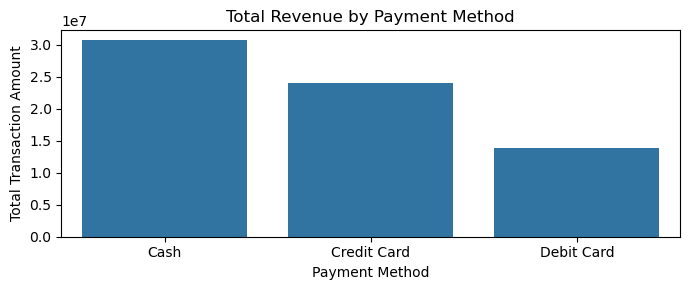

In [17]:
# Analyze transactions by payment method
payment_method_analysis = (
    customer_shopping_data
    .groupby("payment_method")
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(payment_method_analysis)

# Visualize total revenue by payment method
plt.figure(figsize=(7, 3))

sns.barplot(
    data=payment_method_analysis.reset_index(),
    x="payment_method",
    y="Total_Revenue"
)

plt.title("Total Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Transaction Amount")
plt.tight_layout()
plt.show()

#### Revenue Analysis by Day of the Week


,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
day_of_week,,,,
Monday,10119164.19,703.55,14383,43568
Tuesday,9889492.70,695.61,14217,42822
Wednesday,9707632.41,687.51,14120,42443
Thursday,9675628.75,684.81,14129,42469
Friday,9768307.81,680.86,14347,43075
Saturday,9644341.36,682.98,14121,42156
Sunday,9746798.69,689.31,14140,42179


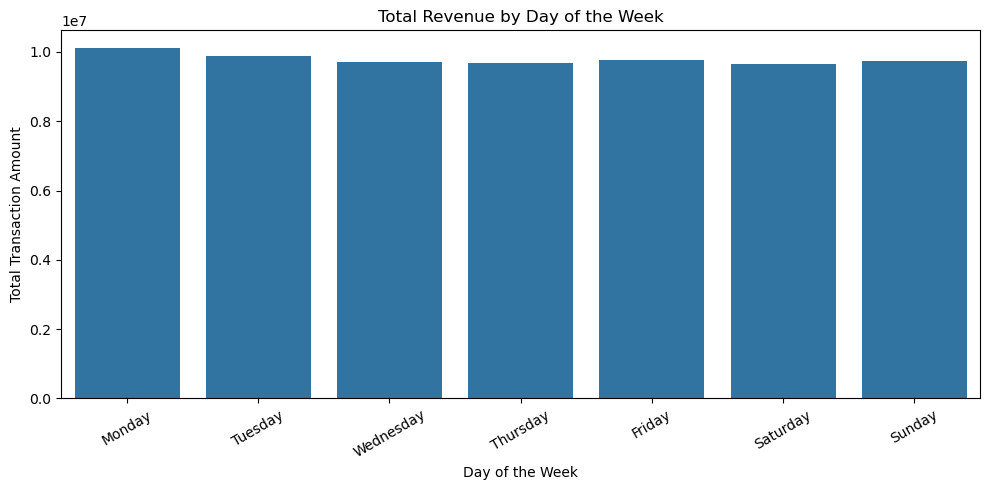

In [18]:

# Extract day of the week
customer_shopping_data["day_of_week"] = (
    customer_shopping_data["invoice_date"].dt.day_name()
)

# Summarize revenue, transactions, and quantity by weekday
weekday_revenue_analysis = (
    customer_shopping_data
    .groupby("day_of_week")
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"
    ])
    .round(2)
)

display(weekday_revenue_analysis)

# Visualize revenue by weekday
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_revenue_analysis.reset_index(),
    x="day_of_week",
    y="Total_Revenue"
)

plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#### Revenue Analysis by Gender

,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
gender,,,,
Female,40931801.62,688.14,59482,178659
Male,27619564.29,690.92,39975,120053


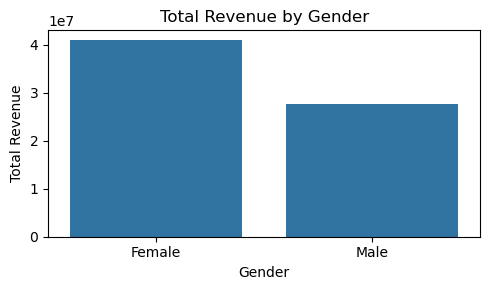

In [19]:

gender_revenue_analysis = (
    customer_shopping_data.groupby("gender")
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(gender_revenue_analysis)

# Visualize total revenue by gender
plt.figure(figsize=(5, 3))
sns.barplot(
    data=gender_revenue_analysis.reset_index(),
    x="gender",
    y="Total_Revenue"
)
plt.title("Total Revenue by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


#### Revenue Analysis by Age Group

,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
age_group,,,,
56–69,18244422.23,686.22,26587,79850
36–45,13603716.89,699.92,19436,58483
46–55,13157097.96,691.90,19016,57086
26–35,13101356.40,687.41,19059,57265
18–25,10444772.43,680.04,15359,46028


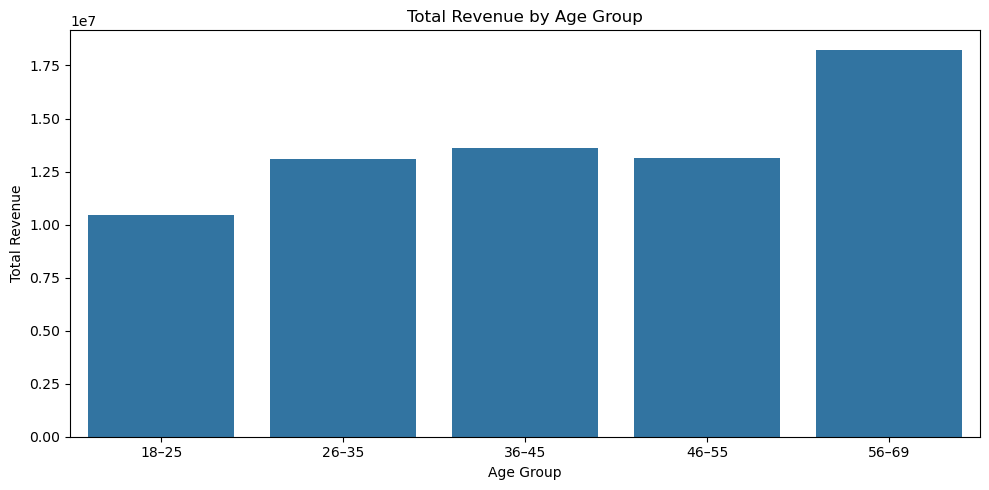

In [20]:

age_group_revenue_analysis = (
    customer_shopping_data.groupby("age_group", observed=True)
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(age_group_revenue_analysis)

# Visualize total revenue by age group
plt.figure(figsize=(10, 5))
sns.barplot(
    data=age_group_revenue_analysis.reset_index(),
    x="age_group",
    y="Total_Revenue"
)
plt.title("Total Revenue by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


#### Revenue Analysis by Shopping Mall

,Total_Revenue,Average_Transaction_Amount,Transaction_Count,Total_Quantity_Sold
shopping_mall,,,,
Mall of Istanbul,13851737.62,694.57,19943,60114
Kanyon,13710755.24,691.66,19823,59457
Metrocity,10249980.07,682.83,15011,44894
Metropol AVM,6937992.99,682.81,10161,30530
Istinye Park,6717077.54,686.75,9781,29465
Zorlu Center,3509649.02,691.56,5075,15234
Cevahir AVM,3433671.84,687.97,4991,14949
Viaport Outlet,3414019.46,694.75,4914,14716
Emaar Square Mall,3390408.31,704.72,4811,14501


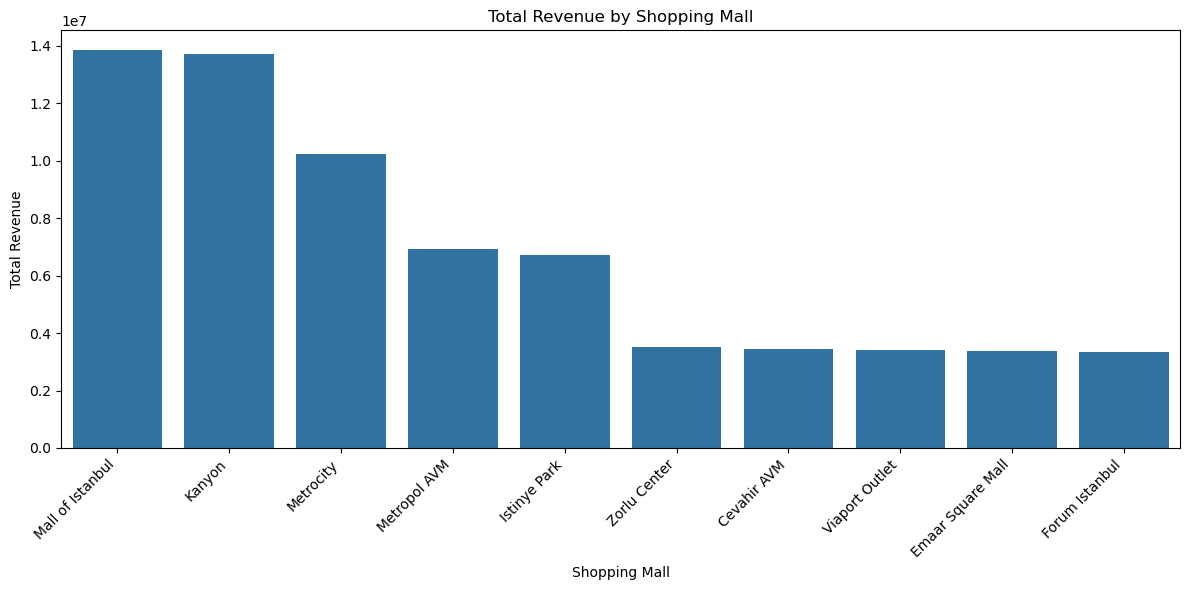

In [21]:

mall_revenue_analysis = (
    customer_shopping_data.groupby("shopping_mall")
    .agg(
        Total_Revenue=("price", "sum"),
        Average_Transaction_Amount=("price", "mean"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(mall_revenue_analysis)

# Visualize total revenue by shopping mall
plt.figure(figsize=(12, 6))
sns.barplot(
    data=mall_revenue_analysis.reset_index(),
    x="shopping_mall",
    y="Total_Revenue"
)
plt.title("Total Revenue by Shopping Mall")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Multivariate Analysis of Customer Shopping Behavior

#### Category, Gender, and Revenue

gender,Female,Male
category,,
Books,132956.40,94020.90
Clothing,18616663.12,12459021.52
Cosmetics,1108432.26,740174.64
Food & Beverage,137873.26,93695.45
Shoes,10746644.02,7388692.87
Souvenir,105288.48,69148.35
Technology,9425850.00,6346200.00
Toys,658094.08,428610.56


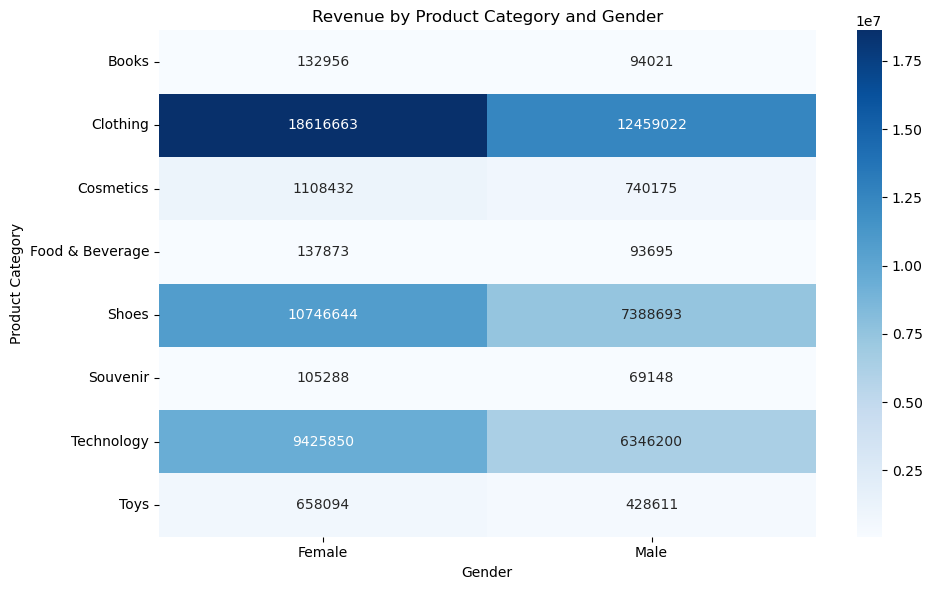

In [22]:

# Calculate revenue by category and gender
category_gender_revenue = pd.pivot_table(
    customer_shopping_data,
    values="price",
    index="category",
    columns="gender",
    aggfunc="sum",
    observed=True,
    fill_value=0
).round(2)

display(category_gender_revenue)

# Visualize revenue by category and gender
plt.figure(figsize=(10, 6))
sns.heatmap(
    category_gender_revenue,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)
plt.title("Revenue by Product Category and Gender")
plt.xlabel("Gender")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [23]:

# Identify the highest-revenue gender for each category
category_gender_revenue["Higher_Revenue_Gender"] = (
    category_gender_revenue[["Female", "Male"]].idxmax(axis=1)
)

display(category_gender_revenue)


gender,Female,Male,Higher_Revenue_Gender
category,,,
Books,132956.40,94020.90,Female
Clothing,18616663.12,12459021.52,Female
Cosmetics,1108432.26,740174.64,Female
Food & Beverage,137873.26,93695.45,Female
Shoes,10746644.02,7388692.87,Female
Souvenir,105288.48,69148.35,Female
Technology,9425850.00,6346200.00,Female
Toys,658094.08,428610.56,Female


#### Age Group, Gender, and Revenue

gender,Female,Male
age_group,,
18–25,6300820.36,4143952.07
26–35,7769309.73,5332046.67
36–45,8152636.02,5451080.87
46–55,7804055.68,5353042.28
56–69,10904979.83,7339442.40


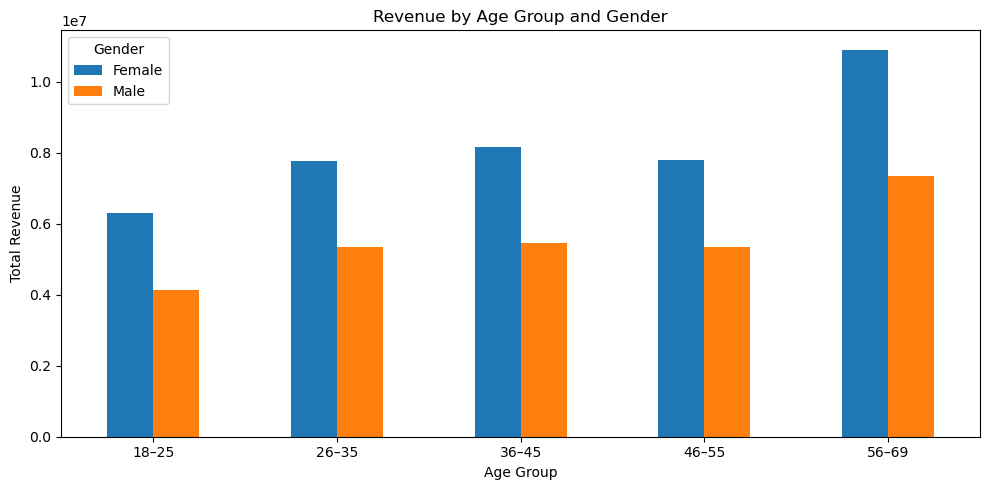

In [24]:

age_gender_revenue = pd.pivot_table(
    customer_shopping_data,
    values="price",
    index="age_group",
    columns="gender",
    aggfunc="sum",
    observed=True,
    fill_value=0
).round(2)

display(age_gender_revenue)

# Visualize revenue by age group and gender
age_gender_revenue.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Revenue by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()


#### Shopping Mall, Category, and Revenue

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
shopping_mall,,,,,,,,
Cevahir AVM,11998.80,1554414.40,88394.84,11992.39,884050.41,8304.84,819000.0,55516.16
Emaar Square Mall,11059.50,1511803.04,92379.52,11030.07,871446.84,8515.98,834750.0,49423.36
Forum Istanbul,11453.40,1572119.12,95225.72,10836.56,875648.03,9090.75,706650.0,55050.24
Istinye Park,20725.20,3050313.20,178741.36,23419.94,1806511.70,18369.18,1509900.0,109096.96
Kanyon,44980.35,6155541.04,372242.30,45474.85,3640031.05,35483.25,3202500.0,214502.40
Mall of Istanbul,46949.85,6245565.04,373787.38,46431.94,3668239.04,34263.33,3220350.0,216151.04
Metrocity,34405.65,4719958.32,272422.00,35375.72,2610139.33,25770.81,2386650.0,165258.24
Metropol AVM,22240.20,3166444.16,185775.54,23984.78,1942750.29,18603.78,1465800.0,112394.24
Viaport Outlet,10908.00,1530708.08,92664.14,11432.78,882850.07,7636.23,823200.0,54620.16


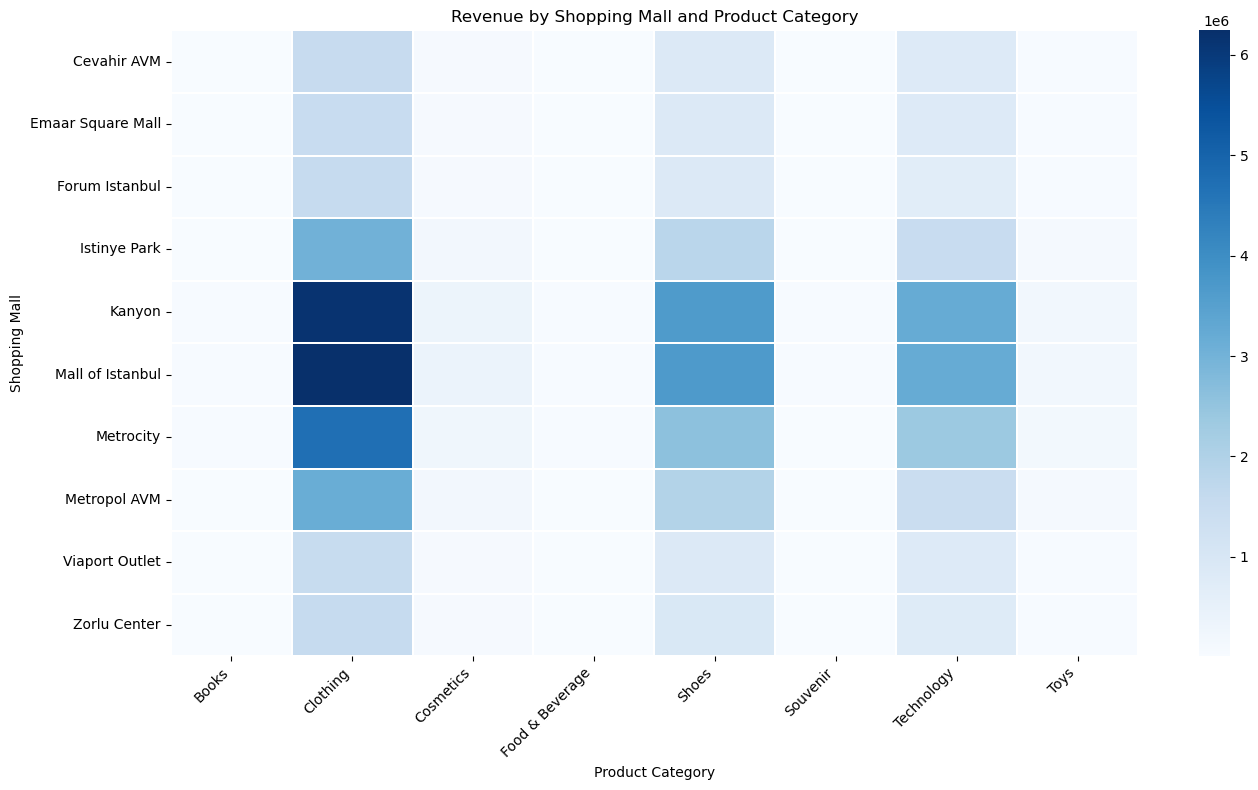

In [25]:

mall_category_revenue = pd.pivot_table(
    customer_shopping_data,
    values="price",
    index="shopping_mall",
    columns="category",
    aggfunc="sum",
    observed=True,
    fill_value=0
).round(2)

display(mall_category_revenue)

# Visualize revenue by mall and category
plt.figure(figsize=(14, 8))
sns.heatmap(
    mall_category_revenue,
    cmap="Blues",
    linewidths=0.3
)
plt.title("Revenue by Shopping Mall and Product Category")
plt.xlabel("Product Category")
plt.ylabel("Shopping Mall")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Correlation Analysis

,age,quantity,price
age,1.0,0.00,0.00
quantity,0.0,1.00,0.34
price,0.0,0.34,1.00


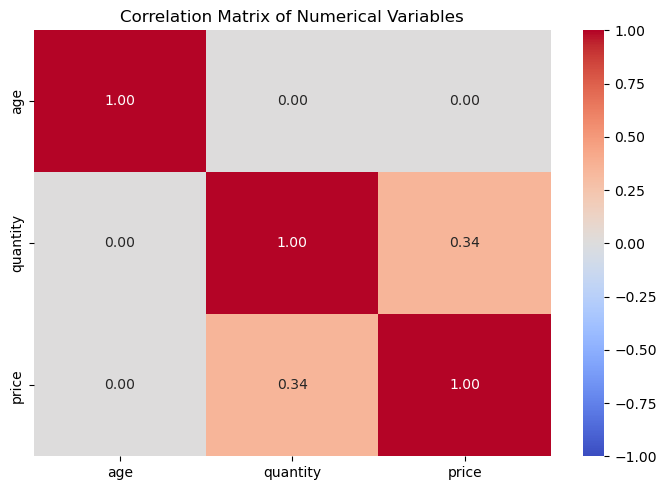

In [26]:

# Select numerical columns
numerical_data = customer_shopping_data[
    ["age", "quantity", "price"]
]

# Calculate correlation matrix
correlation_matrix = numerical_data.corr()

display(correlation_matrix.round(2))

# Visualize correlations
plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix of Numerical Variables")
plt.tight_layout()
plt.show()


### Transaction-Level Spending Analysis

In [27]:
# Analyze transaction amount by customer
customer_spending_analysis = (
    customer_shopping_data
    .groupby("customer_id")
    .agg(
        Total_Spending=("price", "sum"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity=("quantity", "sum")
    )
    .sort_values("Total_Spending", ascending=False)
)

# Display the 10 highest-spending customers
print("Top 10 Customers by Spending:")
display(customer_spending_analysis.head(10).round(2))

# Display overall customer spending statistics
print("\nCustomer Spending Summary:")
display(customer_spending_analysis["Total_Spending"].describe().to_frame().round(2))

# Check whether customers have multiple transactions
print(
    "\nCustomers with Multiple Transactions:",
    (customer_spending_analysis["Transaction_Count"] > 1).sum()
)

Top 10 Customers by Spending:


,Total_Spending,Transaction_Count,Total_Quantity
customer_id,,,
C596151,5250.0,1,5
C107474,5250.0,1,5
C141182,5250.0,1,5
C141193,5250.0,1,5
C630561,5250.0,1,5
C201198,5250.0,1,5
C632313,5250.0,1,5
C200860,5250.0,1,5
C200676,5250.0,1,5



Customer Spending Summary:


,Total_Spending
count,99457.00
mean,689.26
std,941.18
min,5.23
25%,45.45
50%,203.30
75%,1200.32
max,5250.00



Customers with Multiple Transactions: 0


### Monthly Revenue Trend Analysis

,year_month,Total_Revenue,Transaction_Count,Total_Quantity_Sold
0,2021-01,2656422.78,3835,11483
1,2021-02,2358636.34,3407,10179
2,2021-03,2618434.14,3813,11383
3,2021-04,2558825.62,3724,11270
4,2021-05,2662369.93,3848,11620
5,2021-06,2547239.73,3783,11352
6,2021-07,2802468.58,3984,11986
7,2021-08,2632303.32,3723,11205
8,2021-09,2530305.88,3670,10901
9,2021-10,2782418.40,3916,11711


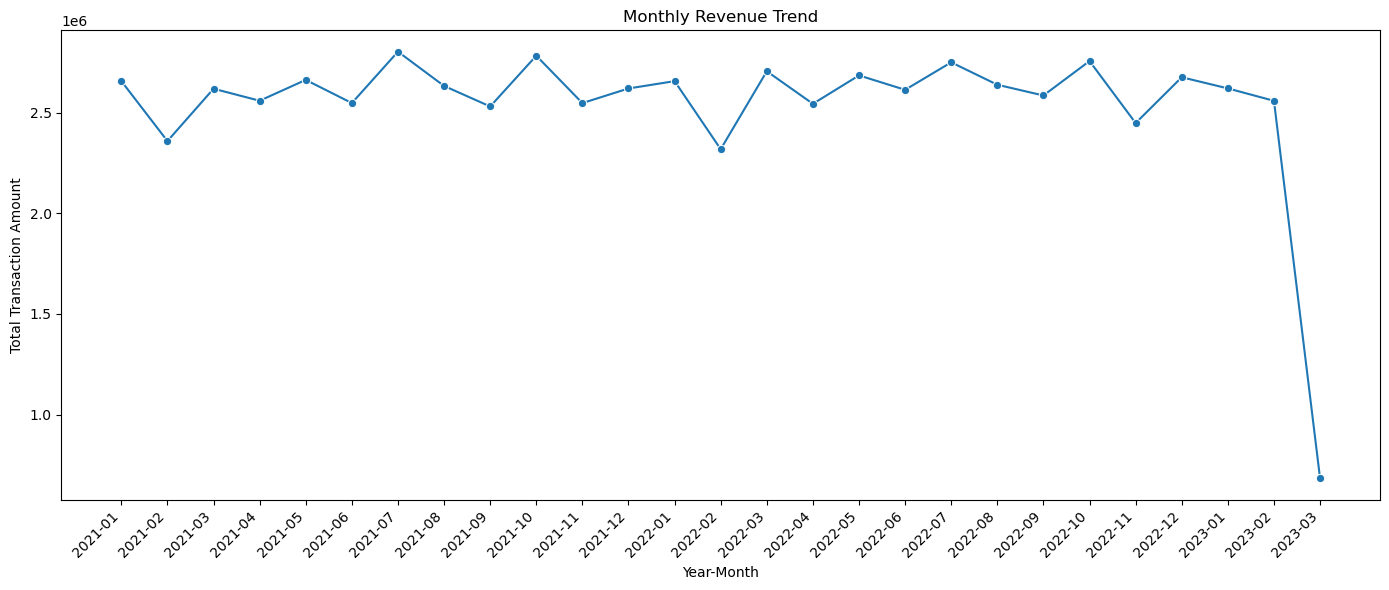

Highest Revenue Month:


,year_month,Total_Revenue,Transaction_Count,Total_Quantity_Sold
6,2021-07,2802468.58,3984,11986



Lowest Revenue Month:


,year_month,Total_Revenue,Transaction_Count,Total_Quantity_Sold
26,2023-03,683721.31,970,2892


March 2023 is incomplete because the dataset ends on March 8, 2023.


In [28]:
# Extract year and month from invoice_date
customer_shopping_data["year_month"] = (
    customer_shopping_data["invoice_date"].dt.to_period("M")
)

# Calculate monthly revenue and transaction count
monthly_revenue_analysis = (
    customer_shopping_data
    .groupby("year_month")
    .agg(
        Total_Revenue=("price", "sum"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .reset_index()
)

# Convert year_month to string for visualization
monthly_revenue_analysis["year_month"] = (
    monthly_revenue_analysis["year_month"].astype(str)
)

display(monthly_revenue_analysis)

# Visualize monthly revenue trend
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue_analysis,
    x="year_month",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Transaction Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Find the highest and lowest monthly revenue
highest_revenue_month = monthly_revenue_analysis.loc[
    monthly_revenue_analysis["Total_Revenue"].idxmax()
]

lowest_revenue_month = monthly_revenue_analysis.loc[
    monthly_revenue_analysis["Total_Revenue"].idxmin()
]

print("Highest Revenue Month:")
display(highest_revenue_month.to_frame().T)

print("\nLowest Revenue Month:")
display(lowest_revenue_month.to_frame().T)

print("March 2023 is incomplete because the dataset ends on March 8, 2023.")

#### Monthly Revenue Across All Years

In [29]:
# Extract month name from invoice_date
customer_shopping_data["month_name"] = (
    customer_shopping_data["invoice_date"].dt.month_name()
)

# Calculate revenue by calendar month across all years
monthly_revenue_by_name = (
    customer_shopping_data
    .groupby("month_name")
    .agg(
        Total_Revenue=("price", "sum"),
        Transaction_Count=("invoice_no", "count"),
        Total_Quantity_Sold=("quantity", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .round(2)
)

display(monthly_revenue_by_name)

print(
    "\nHighest Revenue Month:",
    monthly_revenue_by_name["Total_Revenue"].idxmax()
)

,Total_Revenue,Transaction_Count,Total_Quantity_Sold
month_name,,,
January,7932626.63,11608,34763
February,7235297.32,10482,31343
March,6007346.21,8730,26224
July,5552023.57,7877,23699
October,5538258.09,7764,23477
May,5346926.82,7697,23217
December,5295165.36,7680,23152
August,5270542.03,7635,22921
June,5160345.74,7581,22674



Highest Revenue Month: January


### Business Insights and Recommendations

In [30]:

# Business insights from the analysis

# 1. Top product category
category_revenue = customer_shopping_data.groupby("category")["price"].sum()
print("1. Top Revenue Category:", category_revenue.idxmax())

# 2. Top shopping mall
mall_revenue = customer_shopping_data.groupby("shopping_mall")["price"].sum()
print("2. Top Revenue Shopping Mall:", mall_revenue.idxmax())

# 3. Revenue by gender
gender_revenue = customer_shopping_data.groupby("gender")["price"].sum()
print("3. Highest Revenue Gender:", gender_revenue.idxmax())

# 4. Top calendar month across all years
customer_shopping_data["month_name"] = (
    customer_shopping_data["invoice_date"].dt.month_name()
)
month_revenue = customer_shopping_data.groupby("month_name")["price"].sum()
print("4. Highest Revenue Month:", month_revenue.idxmax())

# 5. Highest-revenue age group and gender combination
age_gender_revenue = pd.pivot_table(
    customer_shopping_data,
    values="price",
    index="age_group",
    columns="gender",
    aggfunc="sum",
    observed=True,
    fill_value=0
)
top_age_group = age_gender_revenue.stack().idxmax()
print("5. Highest Revenue Age Group and Gender:", top_age_group)


1. Top Revenue Category: Clothing
2. Top Revenue Shopping Mall: Mall of Istanbul
3. Highest Revenue Gender: Female
4. Highest Revenue Month: January
5. Highest Revenue Age Group and Gender: ('56–69', 'Female')


### Export

In [31]:

# Save the cleaned dataset
customer_shopping_data.to_csv(
    "customer_shopping_cleaned_python_intership26sep.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
print("Dataset shape:", customer_shopping_data.shape)
print("Missing values:", customer_shopping_data.isnull().sum().sum())
print("Duplicate rows:", customer_shopping_data.duplicated().sum())


Cleaned dataset saved successfully.
Dataset shape: (99457, 14)
Missing values: 0
Duplicate rows: 0


### Python EDA Summary Dashboard

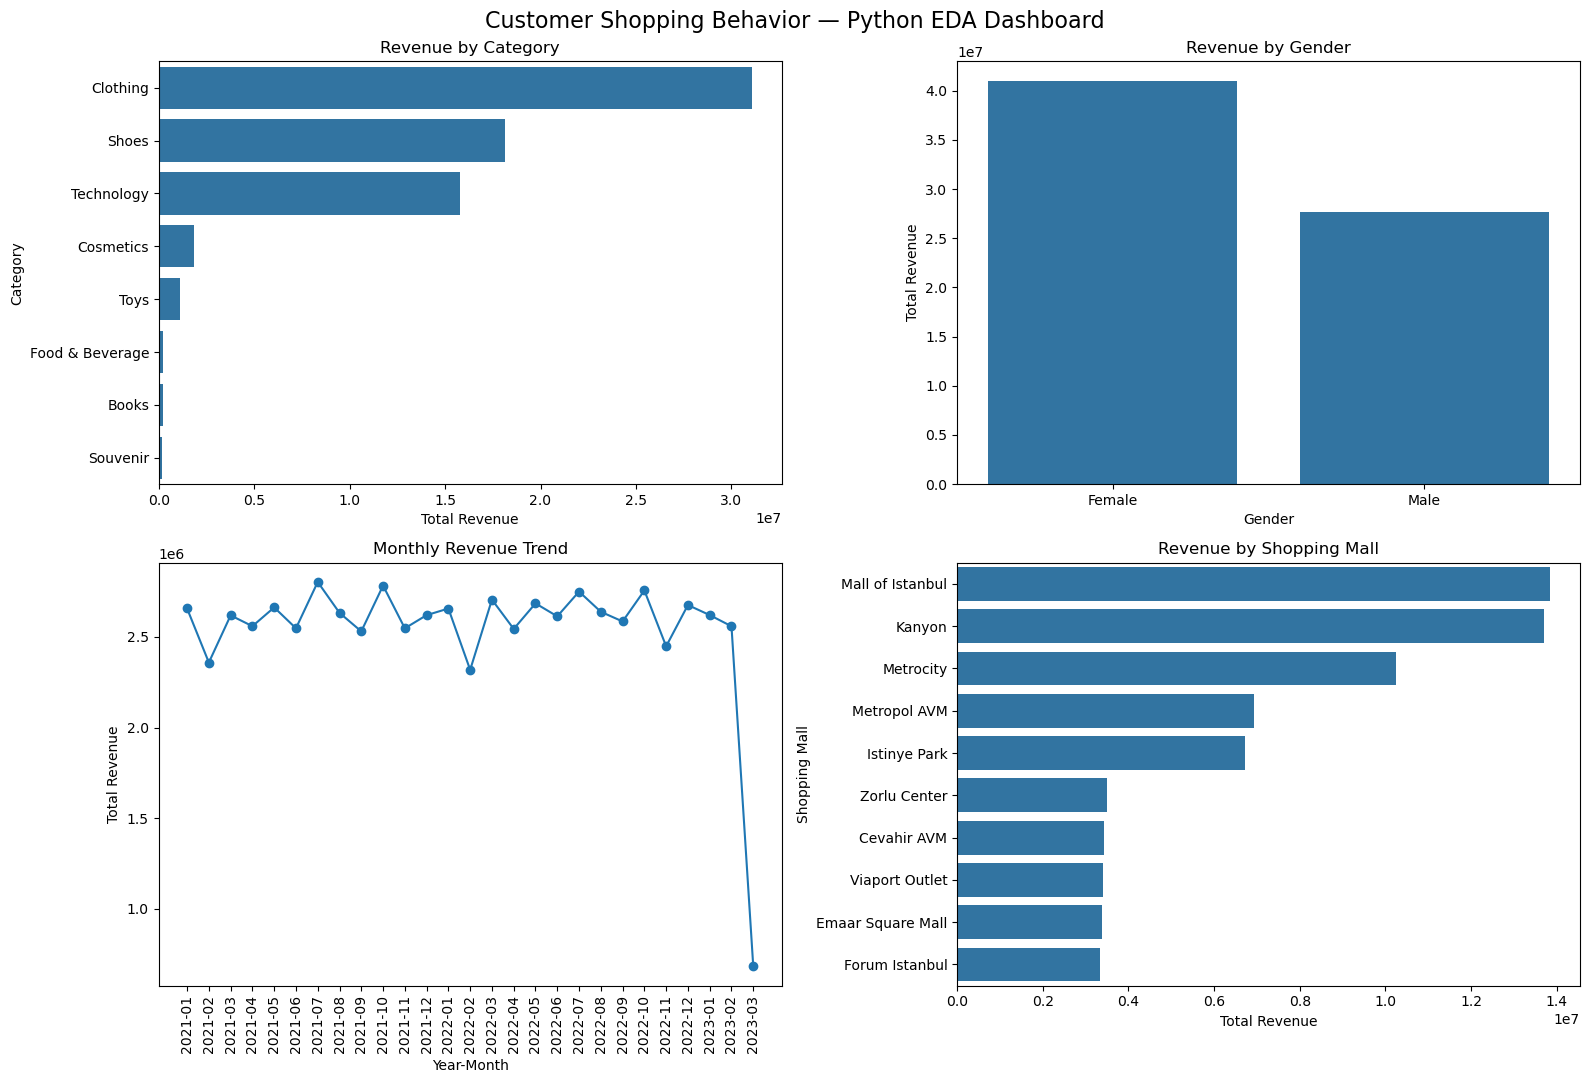

In [32]:

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Revenue by category
category_revenue = (
    customer_shopping_data.groupby("category")["price"]
    .sum()
    .sort_values(ascending=False)
)
sns.barplot(x=category_revenue.values, y=category_revenue.index, ax=axes[0, 0])
axes[0, 0].set_title("Revenue by Category")
axes[0, 0].set_xlabel("Total Revenue")
axes[0, 0].set_ylabel("Category")

# 2. Revenue by gender
gender_revenue = customer_shopping_data.groupby("gender")["price"].sum()
sns.barplot(x=gender_revenue.index, y=gender_revenue.values, ax=axes[0, 1])
axes[0, 1].set_title("Revenue by Gender")
axes[0, 1].set_xlabel("Gender")
axes[0, 1].set_ylabel("Total Revenue")

# 3. Monthly revenue across the timeline
monthly_revenue = (
    customer_shopping_data.groupby(
        customer_shopping_data["invoice_date"].dt.to_period("M")
    )["price"]
    .sum()
)
axes[1, 0].plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)
axes[1, 0].set_title("Monthly Revenue Trend")
axes[1, 0].set_xlabel("Year-Month")
axes[1, 0].set_ylabel("Total Revenue")
axes[1, 0].tick_params(axis="x", rotation=90)

# 4. Revenue by shopping mall
mall_revenue = (
    customer_shopping_data.groupby("shopping_mall")["price"]
    .sum()
    .sort_values(ascending=False)
)
sns.barplot(x=mall_revenue.values, y=mall_revenue.index, ax=axes[1, 1])
axes[1, 1].set_title("Revenue by Shopping Mall")
axes[1, 1].set_xlabel("Total Revenue")
axes[1, 1].set_ylabel("Shopping Mall")

plt.suptitle("Customer Shopping Behavior — Python EDA Dashboard", fontsize=16)
plt.tight_layout()
plt.show()


## Business Questions



The objective of this analysis is to understand customer shopping behavior, identify revenue-generating categories and shopping malls, and discover patterns that can support better business decisions.

1. Which product category generates the highest total revenue?
2. Which shopping mall contributes the highest revenue?
3. Which payment method is used for the most transactions?
4. Which gender contributes the highest total revenue?
5. Which age group generates the highest revenue?
6. Which calendar month generates the highest revenue across all available years?
7. Which day of the week generates the highest revenue?
8. Which product categories sell the highest quantities?
9. How does revenue vary across shopping malls and product categories?
10. What is the relationship between customer age, quantity purchased, and transaction amount?
11. How many transactions and how much revenue does the dataset contain?
12. What business recommendations can be made from the analysis?

## Converting Findings into Business Insights

### 1. Revenue by Product Category
**Finding:** Clothing generated the highest total revenue of 31,075,684.64, while Technology had the highest average transaction amount of 3,156.94.

**Business Insight:** The business can prioritize clothing inventory based on its strong total revenue and develop targeted strategies for high-value technology purchases.

### 2. Revenue by Shopping Mall
**Finding:** Mall of Istanbul generated the highest total revenue of 13,851,737.62, followed by Kanyon with 13,710,755.24.

**Business Insight:** Management can study the sales patterns of these high-performing malls and compare category-level performance to identify opportunities for other locations.

### 3. Revenue by Gender
**Finding:** Female customers contributed 40,931,801.62 in total revenue, compared with 27,619,564.29 from male customers.

**Business Insight:** The business can study category preferences across genders to create relevant marketing campaigns while continuing to serve both customer groups.

### 4. Revenue by Age Group
**Finding:** Customers aged 56–69 generated the highest total revenue among the defined age groups, at 18,244,422.23.

**Business Insight:** The business can examine this group's product preferences and use the findings to improve customer engagement and product recommendations.

### 5. Revenue by Payment Method
**Finding:** Cash was the most frequently used payment method, accounting for 44,447 transactions (44.69% of all transactions).

**Business Insight:** The business should maintain convenient cash-payment facilities while continuing to offer card-payment options.

### 6. Revenue by Calendar Month
**Finding:** January generated the highest combined revenue across all available years, totaling 7,932,626.63.

**Business Insight:** The business can examine January sales patterns and plan inventory and promotions based on recurring demand, while validating this pattern with future data.

### 7. Revenue by Day of the Week
**Finding:** Monday generated the highest total revenue, at 10,119,164.19.

**Business Insight:** The business can review staffing and promotional schedules around weekday demand and monitor whether this pattern continues over time.

### 8. Revenue by Shopping Mall and Product Category
**Finding:** Clothing generated the highest revenue among the product categories across the shopping malls analyzed, although revenue levels varied by location.

**Business Insight:** Mall-specific inventory and promotional strategies can be planned using the revenue contribution of each category at each location.

### 9. Correlation Analysis
**Finding:** Quantity and transaction amount had a positive correlation of approximately 0.34, while age had almost no linear correlation with either quantity or transaction amount.

**Business Insight:** The business can investigate whether larger quantities are associated with higher transaction amounts, but should not interpret correlation as proof of causation.

### Conclusion
The analysis identified important revenue patterns across product categories, shopping malls, payment methods, customer demographics, and shopping dates. These findings can support inventory planning, targeted marketing, and sales monitoring. The recommendations should be validated against additional data before major business decisions are made.

## Generate Business Insights Automatically in Python

In [33]:

# Business findings calculated from the dataset

category_revenue = customer_shopping_data.groupby("category")["price"].sum()
mall_revenue = customer_shopping_data.groupby("shopping_mall")["price"].sum()
gender_revenue = customer_shopping_data.groupby("gender")["price"].sum()
age_group_revenue = customer_shopping_data.groupby(
    "age_group", observed=True
)["price"].sum()
payment_transactions = customer_shopping_data["payment_method"].value_counts()

month_revenue = customer_shopping_data.groupby(
    customer_shopping_data["invoice_date"].dt.month_name()
)["price"].sum()

weekday_revenue = customer_shopping_data.groupby(
    customer_shopping_data["invoice_date"].dt.day_name()
)["price"].sum()

print("BUSINESS INSIGHTS")
print("-" * 40)
print(f"Highest Revenue Category: {category_revenue.idxmax()}")
print(f"Highest Revenue Shopping Mall: {mall_revenue.idxmax()}")
print(f"Highest Revenue Gender: {gender_revenue.idxmax()}")
print(f"Highest Revenue Age Group: {age_group_revenue.idxmax()}")
print(f"Most Used Payment Method: {payment_transactions.idxmax()}")
print(f"Highest Revenue Calendar Month: {month_revenue.idxmax()}")
print(f"Highest Revenue Day of Week: {weekday_revenue.idxmax()}")
print(f"Total Revenue: {customer_shopping_data['price'].sum():,.2f}")
print(f"Total Transactions: {customer_shopping_data['invoice_no'].nunique():,}")


BUSINESS INSIGHTS
----------------------------------------
Highest Revenue Category: Clothing
Highest Revenue Shopping Mall: Mall of Istanbul
Highest Revenue Gender: Female
Highest Revenue Age Group: 56–69
Most Used Payment Method: Cash
Highest Revenue Calendar Month: January
Highest Revenue Day of Week: Monday
Total Revenue: 68,551,365.91
Total Transactions: 99,457


## Final Conclusion



The Customer Shopping Behavior Analysis project was completed using Python in Jupyter Notebook. The dataset was analyzed using Pandas and NumPy for data manipulation and Matplotlib and Seaborn for data visualization.

The analysis involved understanding the dataset, checking data quality, identifying outliers, performing data cleaning and preprocessing, and conducting univariate, bivariate, and multivariate analysis. Revenue patterns were examined across product categories, shopping malls, payment methods, genders, age groups, calendar months, and days of the week.

The findings showed that Clothing generated the highest total revenue among the product categories, January had the highest combined revenue across calendar months, and female customers contributed more revenue than male customers in every age group analyzed. The analysis also helped compare shopping mall performance and customer purchasing patterns.

Overall, this project improved my practical knowledge of Python-based data analysis, exploratory data analysis (EDA), data visualization, and business insight generation. The results can help businesses make more informed decisions about inventory planning, marketing strategies, and customer engagement.

This project demonstrates how data analysis can transform raw shopping transaction data into meaningful information for business decision-making.